# Task 2 · Unemployment Analysis with Python

This notebook explores monthly unemployment estimates for Indian states and asks how the COVID-19 lockdown shows up in the series.

The file is the public **Unemployment in India** dataset. Each row is one state, for one month, split into rural and urban areas. The columns are region, date, frequency, estimated unemployment rate (%), estimated employed people, estimated labour participation rate (%), and area. The months run from **31 May 2019 to 30 June 2020**.


## 1. Setup


In [1]:
from pathlib import Path

%matplotlib inline
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.precision", 2)
pd.set_option("display.max_rows", 40)

DATA_PATH = Path("data") / "Unemployment_in_India.csv"
LOCKDOWN_START = pd.Timestamp("2020-04-01")


## 2. Load, inspect, and convert types

Column names are stripped, fully empty rows are removed, and the date strings are parsed as day-month-year. Region and area text is stripped so `"Bihar"` and `"Bihar "` do not become two places.


In [2]:
raw = pd.read_csv(DATA_PATH)
print("Shape on load:", raw.shape)
print()
print("Column names:", raw.columns.tolist())
print()
print("Data types:")
print(raw.dtypes)
print()
print("Missing values before cleaning:")
print(raw.isnull().sum())


Shape on load: (754, 7)

Column names: ['Region', 'Date', 'Frequency', 'Estimated Unemployment Rate (%)', 'Estimated Employed', 'Estimated Labour Participation Rate (%)', 'Area']

Data types:
Region                                         str
Date                                           str
Frequency                                      str
Estimated Unemployment Rate (%)            float64
Estimated Employed                         float64
Estimated Labour Participation Rate (%)    float64
Area                                           str
dtype: object

Missing values before cleaning:
Region                                     14
Date                                       14
Frequency                                  14
Estimated Unemployment Rate (%)            14
Estimated Employed                         14
Estimated Labour Participation Rate (%)    14
Area                                       14
dtype: int64


In [3]:
df = raw.copy()
df.columns = df.columns.str.strip()
df = df.dropna(how="all")
text_columns = ["Region", "Frequency", "Area"]
for column in text_columns:
    df[column] = df[column].astype(str).str.strip()
df["Date"] = pd.to_datetime(df["Date"], dayfirst=True)
df = df.rename(columns={
    "Estimated Unemployment Rate (%)": "unemployment_rate",
    "Estimated Employed": "employed",
    "Estimated Labour Participation Rate (%)": "labour_participation_rate",
})
df = df.sort_values(["Region", "Area", "Date"]).reset_index(drop=True)

print("Shape after cleaning:", df.shape)
print("Date range:", df["Date"].min().date(), "to", df["Date"].max().date())
print("Regions:", df["Region"].nunique())
print("Frequency values:", df["Frequency"].unique().tolist())
print("Area values:", sorted(df["Area"].unique()))
print()
print("Missing values after cleaning:")
print(df.isnull().sum())
df.head()


Shape after cleaning: (740, 7)
Date range: 2019-05-31 to 2020-06-30
Regions: 28
Frequency values: ['Monthly']
Area values: ['Rural', 'Urban']

Missing values after cleaning:
Region                       0
Date                         0
Frequency                    0
unemployment_rate            0
employed                     0
labour_participation_rate    0
Area                         0
dtype: int64


,Region,Date,Frequency,unemployment_rate,employed,labour_participation_rate,Area
0,Andhra Pradesh,2019-05-31,Monthly,3.65,1.20e+07,43.24,Rural
1,Andhra Pradesh,2019-06-30,Monthly,3.05,1.18e+07,42.05,Rural
2,Andhra Pradesh,2019-07-31,Monthly,3.75,1.21e+07,43.50,Rural
3,Andhra Pradesh,2019-08-31,Monthly,3.32,1.23e+07,43.97,Rural
4,Andhra Pradesh,2019-09-30,Monthly,5.17,1.23e+07,44.68,Rural


The file loads as **754 rows**. **14 of those rows are completely empty**, so they are dropped. The analysis uses **740 rows**, **28 regions**, and both **Rural** and **Urban** areas. Frequency is monthly throughout. After parsing, there are no missing values. Dates cover 31 May 2019 through 30 June 2020, which is long enough to compare the year before the national lockdown with the first lockdown months.


## 3. Descriptive statistics


In [4]:
df[["unemployment_rate", "employed", "labour_participation_rate"]].describe()


,unemployment_rate,employed,labour_participation_rate
count,740.00,7.40e+02,740.00
mean,11.79,7.20e+06,42.63
std,10.72,8.09e+06,8.11
min,0.00,4.94e+04,13.33
25%,4.66,1.19e+06,38.06
50%,8.35,4.74e+06,41.16
75%,15.89,1.13e+07,45.51
max,76.74,4.58e+07,72.57


Across all state-months, the unemployment rate averages about **11.8%**, with a median near **8.4%** and a maximum above **70%**. That long right tail is the lockdown months, not the typical month. Labour participation averages about **42.6%**. `employed` is a headcount, so its mean (about 7.2 million) is not a rate and should not be compared directly with the two percentages.


## 4. Region-wise average unemployment

Rural and urban rows for the same state and month are both kept, and the average below is the mean of every available row for that region.


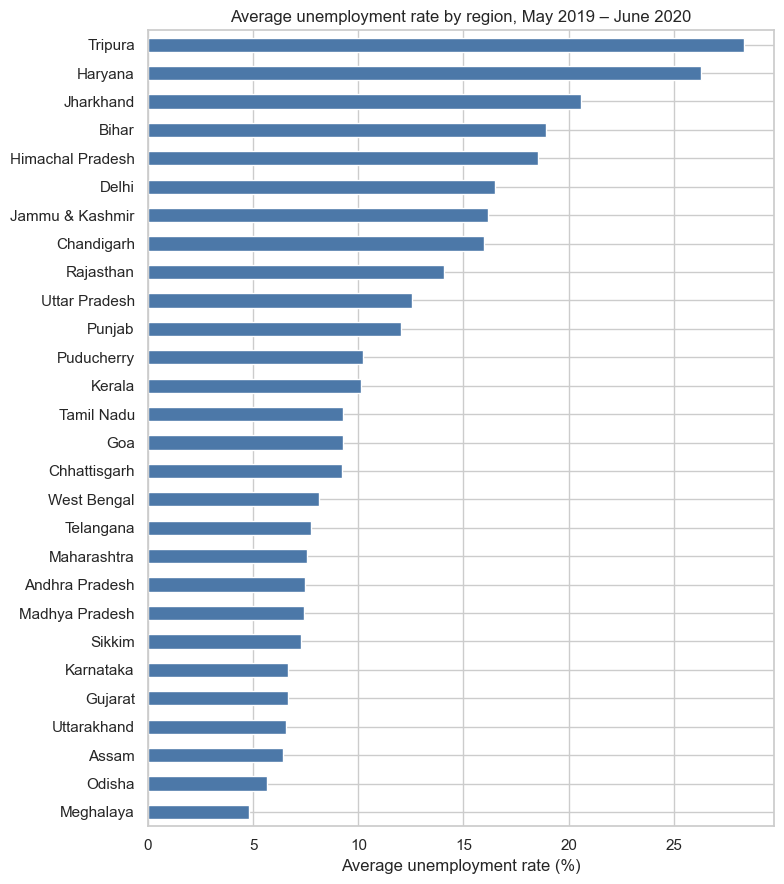

,average_unemployment_rate
Region,
Tripura,28.35
Haryana,26.28
Jharkhand,20.59
Bihar,18.92
Himachal Pradesh,18.54
Delhi,16.50
Jammu & Kashmir,16.19
Chandigarh,15.99
Rajasthan,14.06


In [5]:
region_average = (
    df.groupby("Region")["unemployment_rate"]
    .mean()
    .sort_values(ascending=False)
)
region_plot = region_average.sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(8, 9))
region_plot.plot.barh(ax=ax, color="#4C78A8")
ax.set_xlabel("Average unemployment rate (%)")
ax.set_ylabel("")
ax.set_title("Average unemployment rate by region, May 2019 – June 2020")
fig.tight_layout()
plt.show()
region_average.to_frame("average_unemployment_rate")


Tripura (28.4%), Haryana (26.3%), and Jharkhand (20.6%) have the highest averages over the whole window. Meghalaya (4.8%), Odisha (5.7%), and Assam (6.4%) have the lowest. These averages mix a quiet 2019 with the 2020 shock, so a high rank can mean a state was already high, a state was hit hard in April 2020, or both. The month chart and the state lines below separate those cases.


## 5. Month-wise trend

Each point is the mean unemployment rate across states and across rural and urban areas in that month.


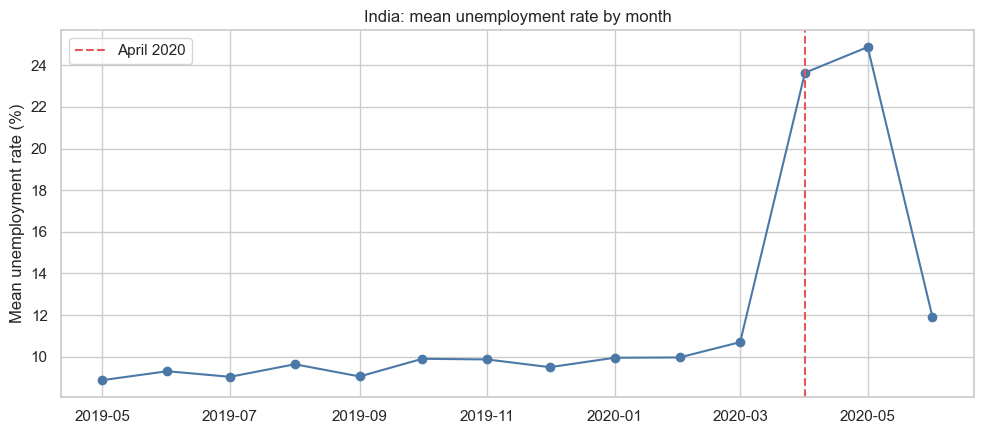

,mean_unemployment_rate
Date,
2019-05-01,8.87
2019-06-01,9.30
2019-07-01,9.03
2019-08-01,9.64
2019-09-01,9.05
2019-10-01,9.90
2019-11-01,9.87
2019-12-01,9.50
2020-01-01,9.95


In [6]:
monthly = df.groupby(df["Date"].dt.to_period("M"))["unemployment_rate"].mean()
monthly.index = monthly.index.to_timestamp()

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(monthly.index, monthly.values, marker="o", color="#4C78A8")
ax.axvline(LOCKDOWN_START, color="#E45756", linestyle="--", label="April 2020")
ax.set_ylabel("Mean unemployment rate (%)")
ax.set_xlabel("")
ax.set_title("India: mean unemployment rate by month")
ax.legend()
fig.tight_layout()
plt.show()
monthly.rename("mean_unemployment_rate").to_frame()


From May 2019 through March 2020 the national mean stays in a narrow band, about **8.9% to 10.7%**. April 2020 breaks that band: the mean jumps to **23.6%**, then **24.9%** in May. June falls back to **11.9%**, close to the old level but still above every pre-lockdown month. The dashed line marks April 2020, the first full month after the nationwide lockdown began on 25 March 2020.


## 6. Unemployment over time in four regions

Bihar, Tamil Nadu, Maharashtra, and Delhi are plotted separately. Where a state has both a rural and an urban row in a month, the line uses their average.


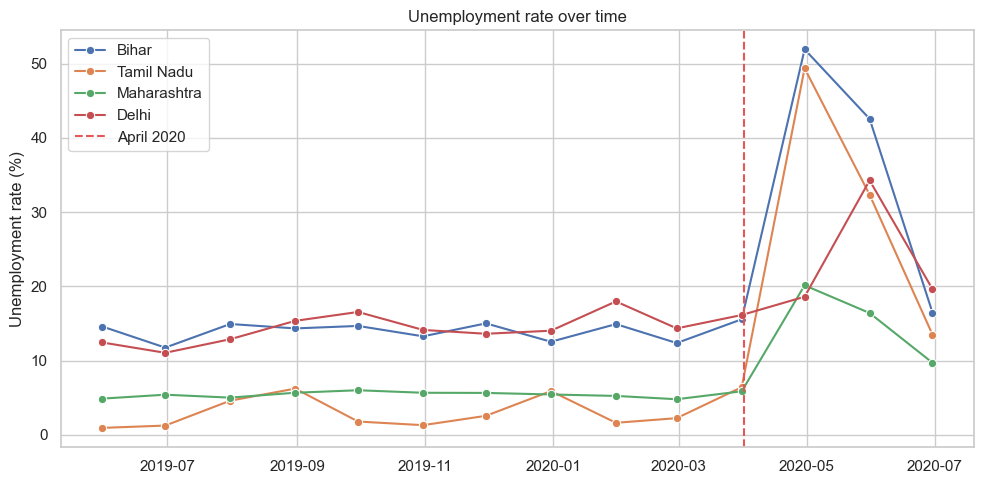

In [7]:
focus_states = ["Bihar", "Tamil Nadu", "Maharashtra", "Delhi"]
state_month = (
    df[df["Region"].isin(focus_states)]
    .groupby(["Date", "Region"], as_index=False)["unemployment_rate"]
    .mean()
)

fig, ax = plt.subplots(figsize=(10, 5))
sns.lineplot(
    data=state_month,
    x="Date",
    y="unemployment_rate",
    hue="Region",
    hue_order=focus_states,
    marker="o",
    ax=ax,
)
ax.axvline(LOCKDOWN_START, color="#E45756", linestyle="--", label="April 2020")
ax.set_ylabel("Unemployment rate (%)")
ax.set_xlabel("")
ax.set_title("Unemployment rate over time")
ax.legend()
fig.tight_layout()
plt.show()


The four lines do not move together before April 2020, and they do not spike by the same amount.

- **Bihar** was already high, mostly between 12% and 16% through 2019. In April 2020 it jumps to **51.9%**, then 42.6% in May, and returns to 16.5% in June.
- **Tamil Nadu** spends most of 2019 under 6%. April 2020 reaches **49.4%**, May is still 32.3%, and June is 13.5%.
- **Maharashtra** stays near 5% until March 2020, rises to **20.1%** in April and 16.4% in May, then eases to 9.7% in June.
- **Delhi** was already elevated, around 11% to 18%. April (18.6%) is inside that old range. The shock arrives in **May, at 34.3%**, and June is still 19.6%.

Same national event, four different shapes: a state that was already high and then doubled, a low state that briefly looked like Bihar, a smaller spike, and a delayed peak.


## 7. Top 10 regions by average unemployment rate


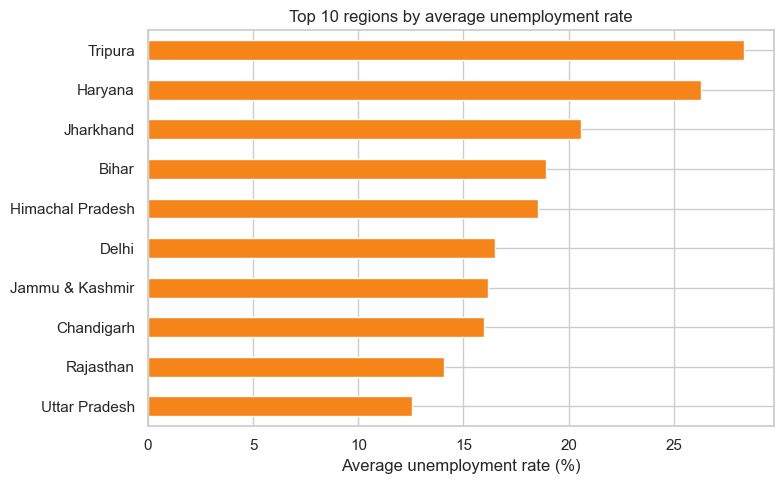

In [8]:
top10 = region_average.head(10).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(8, 5))
top10.plot.barh(ax=ax, color="#F58518")
ax.set_xlabel("Average unemployment rate (%)")
ax.set_ylabel("")
ax.set_title("Top 10 regions by average unemployment rate")
fig.tight_layout()
plt.show()


The ten highest averages are Tripura, Haryana, Jharkhand, Bihar, Himachal Pradesh, Delhi, Jammu & Kashmir, Chandigarh, Rajasthan, and Uttar Pradesh. Tripura leads at about **28.4%** and Uttar Pradesh closes the list at about **12.6%**. Because this ranking uses the full May 2019–June 2020 window, it is not a ranking of the April 2020 shock alone. Tamil Nadu, for example, had one of the sharpest April spikes and still does not appear here, because its 2019 rates were very low.


## 8. Correlation heatmap

The source file has an unemployment rate and a labour participation rate. It does not have an employment rate. `employed` is a person count, so it is the wrong unit for a correlation with two percentages.

The employment rate used here is the estimated share of the working-age population that is employed:

`employment rate = labour participation rate × (100 − unemployment rate) / 100`

Labour participation is the share of working-age people in the labour force. Unemployment is the share of that labour force without work. Multiplying them estimates the share of working-age people who are employed.


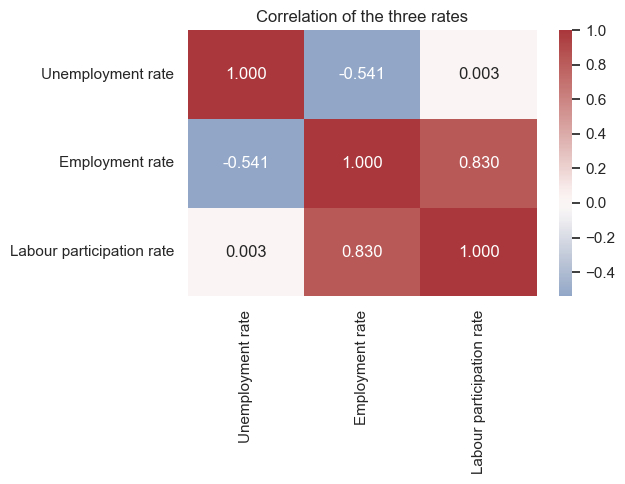

In [9]:
# Estimated percent of the working-age population that is employed.
df["employment_rate"] = (
    df["labour_participation_rate"] * (100 - df["unemployment_rate"]) / 100
)

rate_columns = {
    "unemployment_rate": "Unemployment rate",
    "employment_rate": "Employment rate",
    "labour_participation_rate": "Labour participation rate",
}
correlation = df[list(rate_columns)].corr()
correlation.index = rate_columns.values()
correlation.columns = rate_columns.values()

fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(correlation, annot=True, fmt=".3f", cmap="vlag", center=0, ax=ax)
ax.set_title("Correlation of the three rates")
fig.tight_layout()
plt.show()


Unemployment and labour participation are essentially **uncorrelated (0.003)** across these rows. States and months with high unemployment are not reliably the ones with low participation. The derived employment rate moves with labour participation (**0.830**) and against unemployment (**−0.541**), which is what the formula implies: participation sets the pool of workers, and unemployment removes people from that pool. A near-zero correlation between the two source rates is still compatible with both rates shifting during lockdown. The period comparison in the next section is the right place to see that shift, because a single correlation mixes 28 regions and 14 months.


## 9. Pre-COVID and post-COVID

India's nationwide lockdown started on 25 March 2020. This file is monthly, and the March reading (10.7%) is still inside the 2019 band, so March stays in the pre-COVID period. **Pre-COVID is every row before 1 April 2020. Post-COVID is April, May, and June 2020.**


Pre-COVID rows: 588 | 2019-05-31 to 2020-03-31
Post-COVID rows: 152 | 2020-04-30 to 2020-06-30



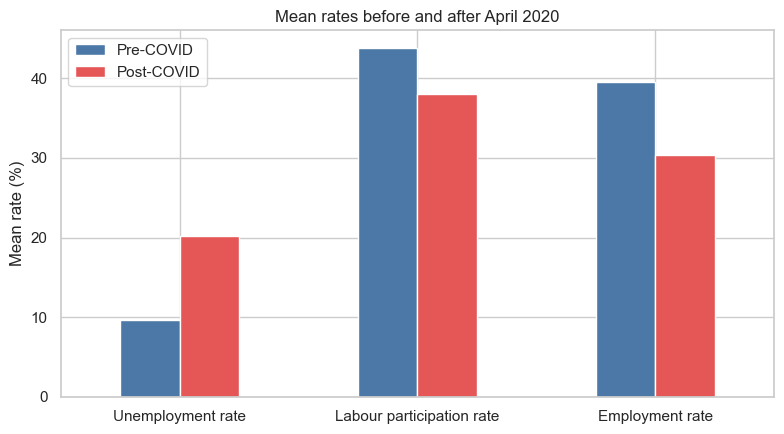

,Pre-COVID,Post-COVID,Change (percentage points)
Unemployment rate,9.61,20.19,10.58
Labour participation rate,43.82,38.05,-5.77
Employment rate,39.47,30.37,-9.10


In [10]:
pre_covid = df[df["Date"] < LOCKDOWN_START]
post_covid = df[df["Date"] >= LOCKDOWN_START]
rate_labels = {
    "unemployment_rate": "Unemployment rate",
    "labour_participation_rate": "Labour participation rate",
    "employment_rate": "Employment rate",
}

comparison = pd.DataFrame({
    "Pre-COVID": pre_covid[list(rate_labels)].mean(),
    "Post-COVID": post_covid[list(rate_labels)].mean(),
})
comparison.index = [rate_labels[name] for name in comparison.index]
comparison["Change (percentage points)"] = comparison["Post-COVID"] - comparison["Pre-COVID"]

print("Pre-COVID rows:", len(pre_covid), "|", pre_covid["Date"].min().date(), "to", pre_covid["Date"].max().date())
print("Post-COVID rows:", len(post_covid), "|", post_covid["Date"].min().date(), "to", post_covid["Date"].max().date())
print()

fig, ax = plt.subplots(figsize=(8, 4.5))
comparison[["Pre-COVID", "Post-COVID"]].plot.bar(ax=ax, color=["#4C78A8", "#E45756"], rot=0)
ax.set_ylabel("Mean rate (%)")
ax.set_xlabel("")
ax.set_title("Mean rates before and after April 2020")
fig.tight_layout()
plt.show()
comparison


The mean unemployment rate rises from **9.61%** before April 2020 to **20.19%** in April–June 2020, an increase of **10.6 percentage points**. The mean labour participation rate falls from **43.82%** to **38.05%**. The derived employment rate falls from **39.47%** to **30.37%**.

The unemployment change is not a small drift. The month chart shows it is concentrated in April and May, with June already much closer to the old level. The post-COVID mean is therefore an average of two extreme months and one recovery month, not a new plateau that lasts through June.

Two limits are worth keeping in view. The post-COVID window is only three months and 152 rows, against 588 rows before April. And the series ends in June 2020, so this notebook does not say how long the recovery took after that.


## 10. What the data shows

Unemployment in this dataset is stable from May 2019 through March 2020, then rises sharply in April and May 2020 as the lockdown takes hold. The national mean goes from about 10% to about 25%, and the employed share of the working-age population drops by about 9 percentage points. June 2020 brings the national mean most of the way back, to 11.9%.

The state lines show that the national average hides different local stories. Bihar and Tamil Nadu both pass 49% in April, Maharashtra peaks near 20%, and Delhi's worst month is May rather than April. A ranking of average rates over the whole period is a different list again: Tripura and Haryana lead it, while Tamil Nadu's sharp but short spike is diluted by a low 2019.
